# Decision Tree: Klasifikasi Tanda Retinopati Diabetik
Bagian: Abid Ra'fad Aziz (tuning, pruning, feature importance). Data: unscaled, hasil preprocessing (916 latih / 230 uji, random_state=42).

## 1. Import dan upload data

In [1]:
import os, joblib, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import files
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

NEEDED = ["train_19fitur_unscaled.csv", "test_19fitur_unscaled.csv",
          "train_17fitur_unscaled.csv", "test_17fitur_unscaled.csv"]

if not all(os.path.exists(f) for f in NEEDED):
    files.upload()   # pilih keempat CSV sekaligus

missing = [f for f in NEEDED if not os.path.exists(f)]
assert not missing, f"File belum ada: {missing}. Isi folder: {os.listdir()}"
print("Semua file ada.")

Saving test_17fitur_unscaled.csv to test_17fitur_unscaled.csv
Saving train_17fitur_unscaled.csv to train_17fitur_unscaled.csv
Saving test_19fitur_unscaled.csv to test_19fitur_unscaled.csv
Saving train_19fitur_unscaled.csv to train_19fitur_unscaled.csv
Semua file ada.


## 2. Load data dan sanity check

In [2]:
def load(n):
    tr = pd.read_csv(f"train_{n}_unscaled.csv")
    te = pd.read_csv(f"test_{n}_unscaled.csv")
    return tr.drop(columns="label"), tr["label"], te.drop(columns="label"), te["label"]

data = {n: load(n) for n in ["19fitur", "17fitur"]}
for n, (Xtr, ytr, Xte, yte) in data.items():
    print(n, "| train", Xtr.shape, "test", Xte.shape,
          "| kelas train", ytr.value_counts().sort_index().to_dict(),
          "| kelas test", yte.value_counts().sort_index().to_dict())
# Harus: train 916, test 230; train {0:432, 1:484}; test {0:108, 1:122}
# 19 fitur -> 19 kolom, 17 fitur -> 17 kolom

19fitur | train (916, 19) test (230, 19) | kelas train {0: 432, 1: 484} | kelas test {0: 108, 1: 122}
17fitur | train (916, 17) test (230, 17) | kelas train {0: 432, 1: 484} | kelas test {0: 108, 1: 122}


## 3. Konfigurasi, fungsi evaluasi, dan baseline

In [3]:
SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # samakan dengan Elvin
REFIT = "recall"   # fokus proyek: sensitivitas. Samakan dengan k-NN (recall atau f1)

def evaluate(model, X, y):
    p = model.predict(X); pr = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p),
                recall=recall_score(y, p), f1=f1_score(y, p),
                roc_auc=roc_auc_score(y, pr), TN=tn, FP=fp, FN=fn, TP=tp)

base_models, base_res = {}, {}
for n, (Xtr, ytr, Xte, yte) in data.items():
    b = DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr)
    base_models[n] = b
    base_res[n] = evaluate(b, Xte, yte)
    print(f"{n} baseline | acc train {b.score(Xtr, ytr):.4f} | acc test {b.score(Xte, yte):.4f}"
          f" | depth {b.get_depth()} | leaves {b.get_n_leaves()}")

19fitur baseline | acc train 1.0000 | acc test 0.6000 | depth 22 | leaves 181
17fitur baseline | acc train 1.0000 | acc test 0.6435 | depth 22 | leaves 178


## 4. Tuning hyperparameter (GridSearchCV, hanya data latih)

In [4]:
grid_params = {
    "max_depth": list(range(2, 16)),
    "min_samples_leaf": [1, 2, 5, 10],
    "min_samples_split": [2, 5, 10],
    "ccp_alpha": [0, 0.001, 0.005, 0.01, 0.02],
}

grids, tuned_models, tuned_res = {}, {}, {}
for n, (Xtr, ytr, Xte, yte) in data.items():
    g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), grid_params,
                     scoring=["recall", "f1", "roc_auc", "accuracy"],
                     refit=REFIT, cv=cv, n_jobs=-1)
    g.fit(Xtr, ytr)
    grids[n] = g; tuned_models[n] = g.best_estimator_
    tuned_res[n] = evaluate(g.best_estimator_, Xte, yte)
    i = g.best_index_
    print(f"\n{n} best params: {g.best_params_}")
    print(f"  CV recall {g.cv_results_['mean_test_recall'][i]:.4f} | "
          f"CV f1 {g.cv_results_['mean_test_f1'][i]:.4f} | "
          f"CV auc {g.cv_results_['mean_test_roc_auc'][i]:.4f}")


19fitur best params: {'ccp_alpha': 0, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 2}
  CV recall 0.6240 | CV f1 0.6216 | CV auc 0.6302

17fitur best params: {'ccp_alpha': 0, 'max_depth': 11, 'min_samples_leaf': 5, 'min_samples_split': 2}
  CV recall 0.6282 | CV f1 0.6361 | CV auc 0.6580


## 5. Kurva pengaruh max_depth dan pruning (ccp_alpha)

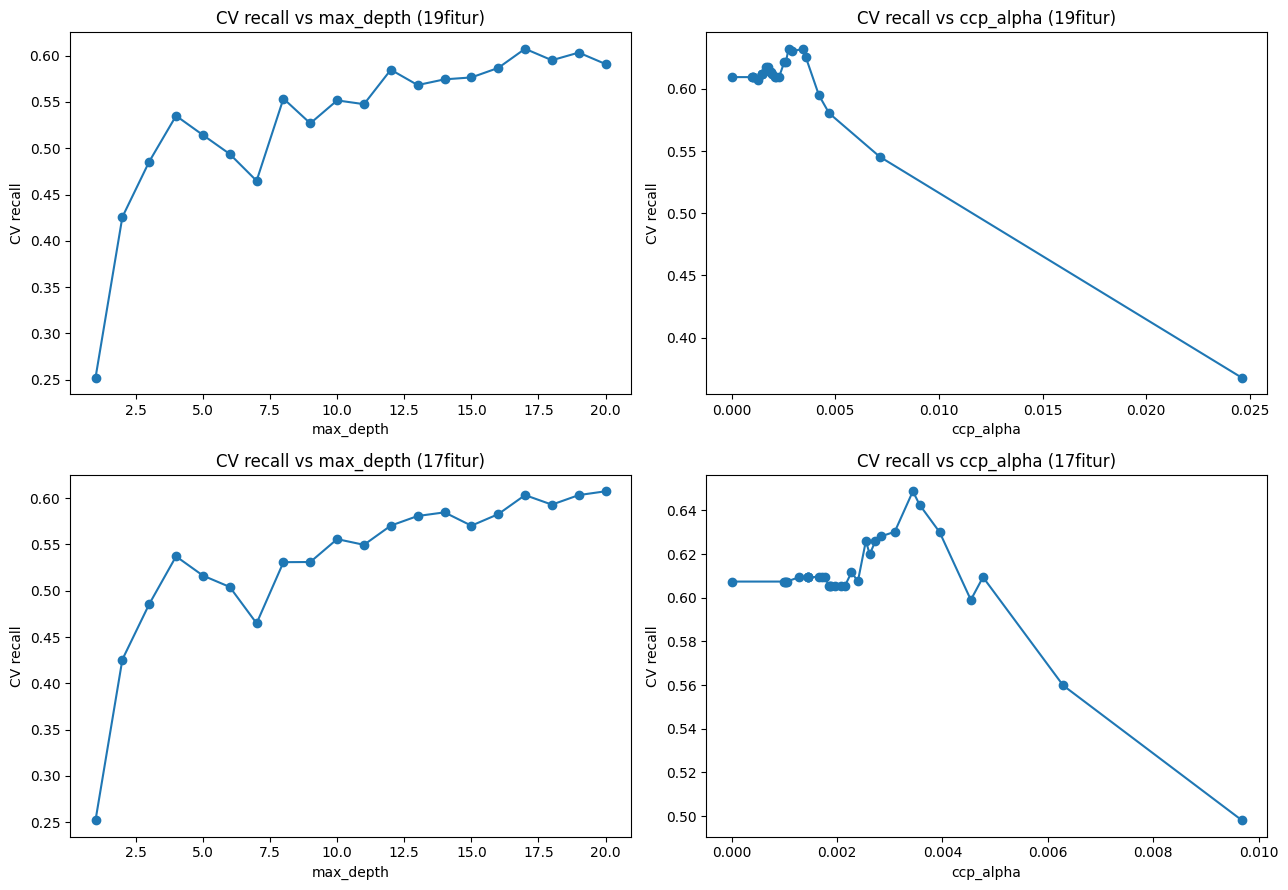

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, (n, (Xtr, ytr, Xte, yte)) in enumerate(data.items()):
    # (a) CV recall vs max_depth (parameter lain default)
    depths = range(1, 21)
    sc = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED),
                          Xtr, ytr, cv=cv, scoring="recall").mean() for d in depths]
    axes[r, 0].plot(list(depths), sc, marker="o")
    axes[r, 0].set(title=f"CV recall vs max_depth ({n})", xlabel="max_depth", ylabel="CV recall")

    # (b) CV recall vs ccp_alpha dari pruning path
    path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xtr, ytr)
    alphas = path.ccp_alphas[:-1]
    alphas = alphas[::max(1, len(alphas)//25)]
    sc = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=SEED),
                          Xtr, ytr, cv=cv, scoring="recall").mean() for a in alphas]
    axes[r, 1].plot(alphas, sc, marker="o")
    axes[r, 1].set(title=f"CV recall vs ccp_alpha ({n})", xlabel="ccp_alpha", ylabel="CV recall")
plt.tight_layout(); plt.savefig("tuning_pruning_curve.png", dpi=150); plt.show()

## 6. Evaluasi final di data uji

In [6]:
rows = {}
for n in data:
    rows[(n, "baseline")] = base_res[n]
    rows[(n, "tuned")] = tuned_res[n]
hasil = pd.DataFrame(rows).T
hasil[["TN", "FP", "FN", "TP"]] = hasil[["TN", "FP", "FN", "TP"]].astype(int)
display(hasil.round(4))

for n, m in tuned_models.items():
    print(n, "| depth", m.get_depth(), "| leaves", m.get_n_leaves(), "| params:", grids[n].best_params_)

accuracy  precision  recall      f1  roc_auc  TN  FP  FN  TP
19fitur baseline    0.6000     0.6316  0.5902  0.6102   0.6006  66  42  50  72
        tuned       0.6261     0.6607  0.6066  0.6325   0.6785  70  38  48  74
17fitur baseline    0.6435     0.6786  0.6230  0.6496   0.6448  72  36  46  76
        tuned       0.6826     0.7290  0.6393  0.6812   0.7329  79  29  44  78

19fitur | depth 15 | leaves 101 | params: {'ccp_alpha': 0, 'max_depth': 15, 'min_samples_leaf': 5, 'min_samples_split': 2}
17fitur | depth 11 | leaves 76 | params: {'ccp_alpha': 0, 'max_depth': 11, 'min_samples_leaf': 5, 'min_samples_split': 2}


## 7. Feature importance


19fitur


,gini_importance,permutation_recall
ma1,0.2249,0.0743
macula_opticdisc_distance,0.1002,0.0254
exudate1,0.0960,-0.0128
exudate2,0.0841,-0.0391
exudate7,0.0750,-0.0284
ma2,0.0675,-0.0240
opticdisc_diameter,0.0551,0.0205
ma5,0.0511,0.0036
ma3,0.0509,0.0158
exudate8,0.0476,0.0219



17fitur


,gini_importance,permutation_recall
ma1,0.2419,0.1115
exudate1,0.1170,0.0128
macula_opticdisc_distance,0.1126,0.0172
exudate7,0.0854,0.0030
ma3,0.0790,0.0071
exudate8,0.0549,0.0219
ma5,0.0530,0.0309
exudate4,0.0442,0.0189
opticdisc_diameter,0.0424,0.0153
exudate2,0.0415,-0.0361


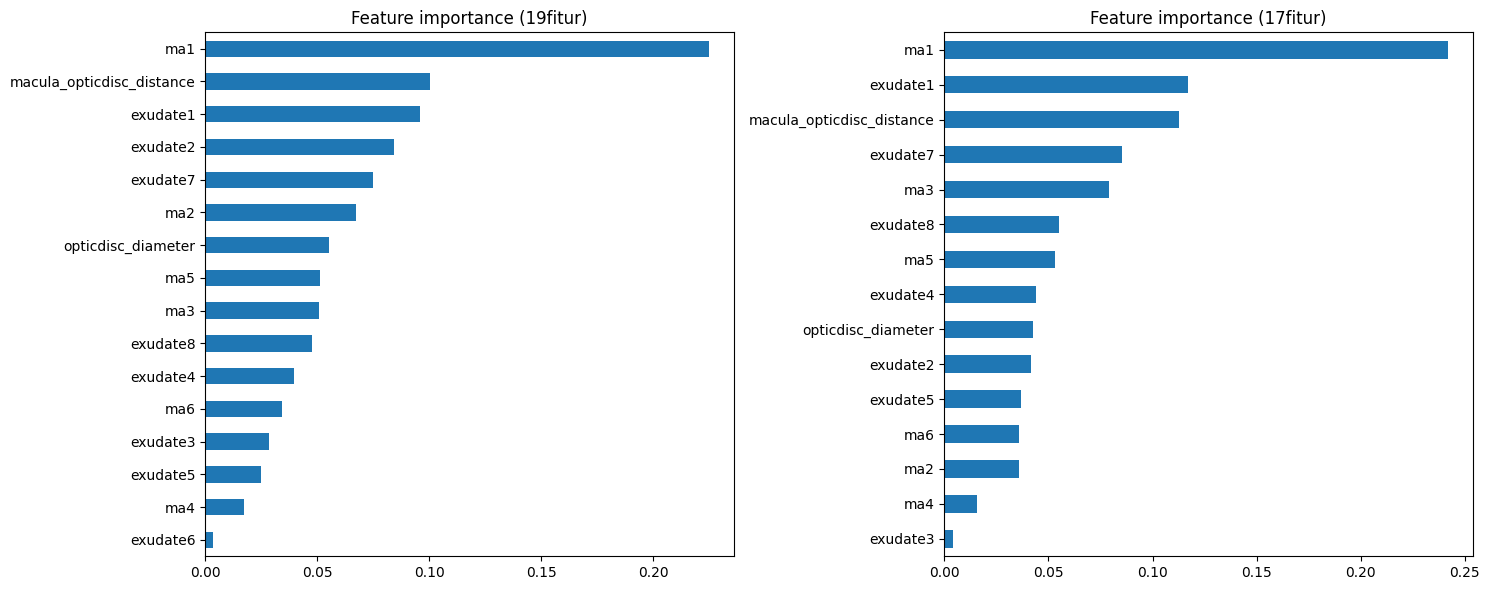

In [7]:
imp_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (n, m) in zip(axes, tuned_models.items()):
    Xte, yte = data[n][2], data[n][3]
    imp = pd.Series(m.feature_importances_, index=Xte.columns)
    perm = permutation_importance(m, Xte, yte, scoring="recall", n_repeats=30, random_state=SEED)
    imp_tables[n] = pd.DataFrame({"gini_importance": imp,
                                  "permutation_recall": perm.importances_mean}
                                 ).sort_values("gini_importance", ascending=False)
    imp[imp > 0].sort_values().plot.barh(ax=ax, title=f"Feature importance ({n})")
    print(f"\n{n}"); display(imp_tables[n].head(10).round(4))
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

# Catatan: exudate3 dan exudate4 identik, ma1-ma6 berkorelasi sangat tinggi,
# jadi importance bisa terbagi/dipilih salah satu. Jelaskan di laporan.

## 8. Visualisasi dan aturan tree

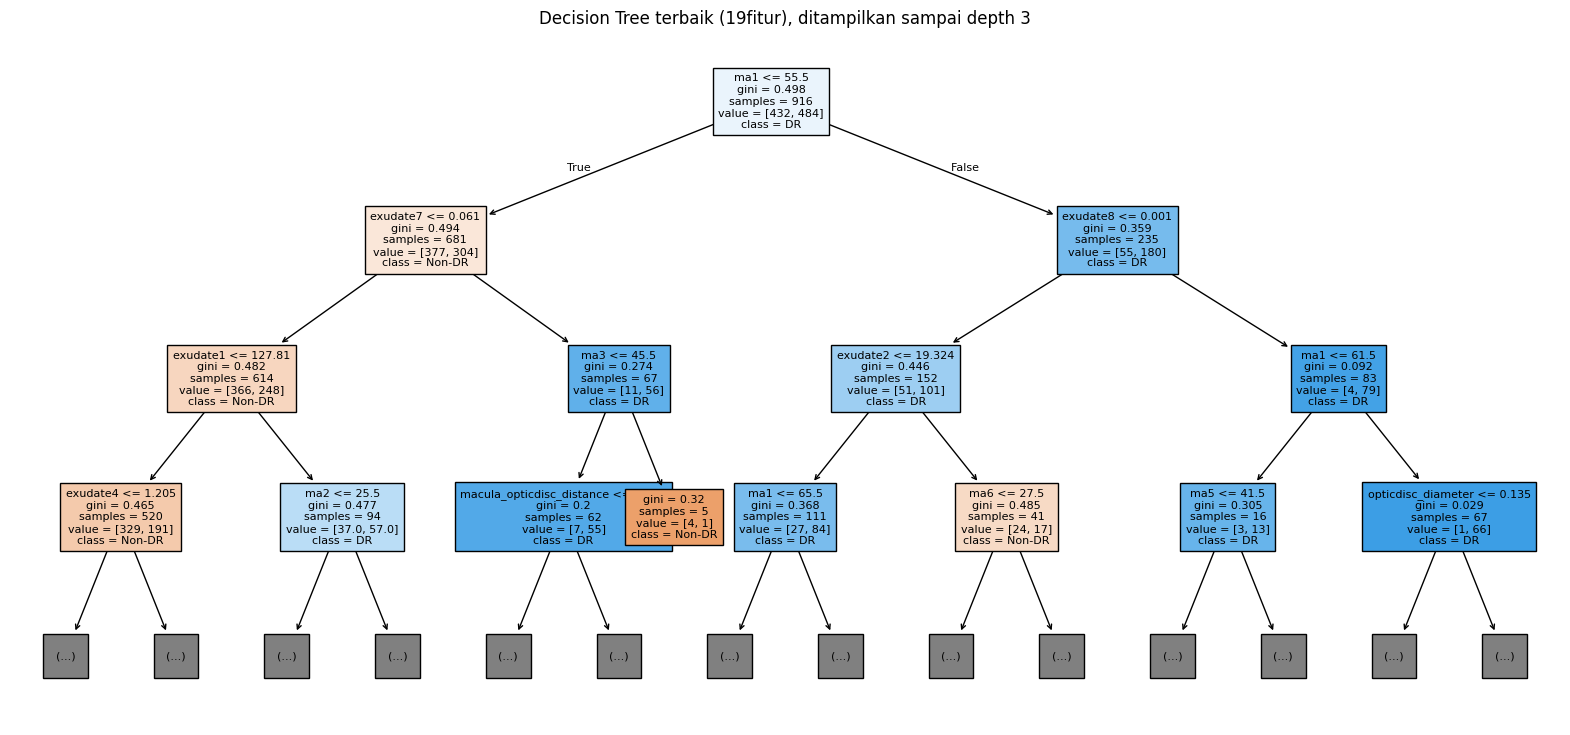

=== 19fitur ===
|--- ma1 <= 55.50
|   |--- exudate7 <= 0.06
|   |   |--- exudate1 <= 127.81
|   |   |   |--- exudate4 <= 1.21
|   |   |   |   |--- truncated branch of depth 10
|   |   |   |--- exudate4 >  1.21
|   |   |   |   |--- truncated branch of depth 12
|   |   |--- exudate1 >  127.81
|   |   |   |--- ma2 <= 25.50
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- ma2 >  25.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- exudate7 >  0.06
|   |   |--- ma3 <= 45.50
|   |   |   |--- macula_opticdisc_distance <= 0.57
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- macula_opticdisc_distance >  0.57
|   |   |   |   |--- class: 1
|   |   |--- ma3 >  45.50
|   |   |   |--- class: 0
|--- ma1 >  55.50
|   |--- exudate8 <= 0.00
|   |   |--- exudate2 <= 19.32
|   |   |   |--- ma1 <= 65.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- ma1 >  65.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- exudate2 >  19.32
|

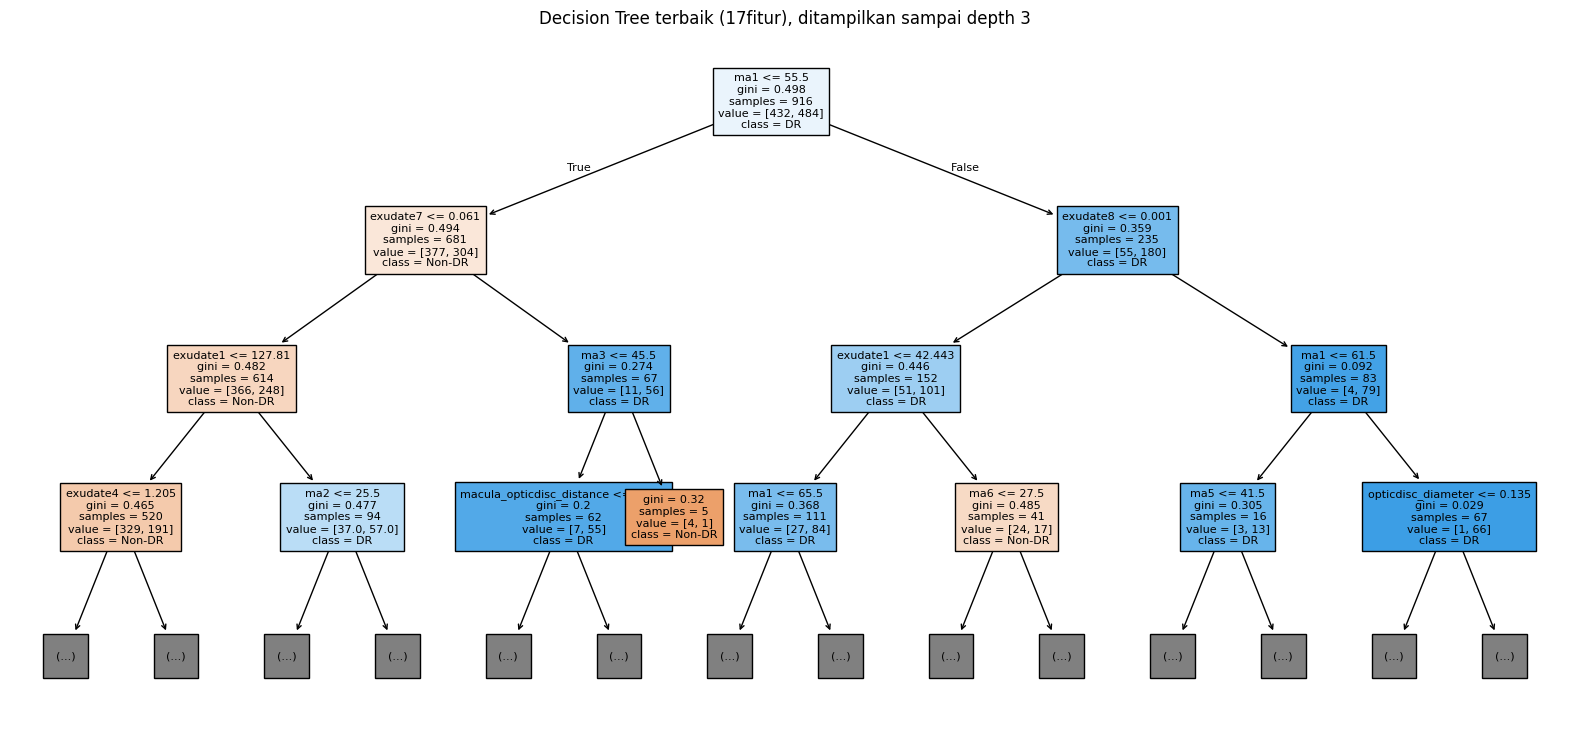

=== 17fitur ===
|--- ma1 <= 55.50
|   |--- exudate7 <= 0.06
|   |   |--- exudate1 <= 127.81
|   |   |   |--- exudate4 <= 1.21
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- exudate4 >  1.21
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- exudate1 >  127.81
|   |   |   |--- ma2 <= 25.50
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- ma2 >  25.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- exudate7 >  0.06
|   |   |--- ma3 <= 45.50
|   |   |   |--- macula_opticdisc_distance <= 0.57
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- macula_opticdisc_distance >  0.57
|   |   |   |   |--- class: 1
|   |   |--- ma3 >  45.50
|   |   |   |--- class: 0
|--- ma1 >  55.50
|   |--- exudate8 <= 0.00
|   |   |--- exudate1 <= 42.44
|   |   |   |--- ma1 <= 65.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- ma1 >  65.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- exudate1 >  42.44
|  

In [8]:
for n, m in tuned_models.items():
    cols = list(data[n][0].columns)
    plt.figure(figsize=(20, 9))
    plot_tree(m, max_depth=3, feature_names=cols, class_names=["Non-DR", "DR"],
              filled=True, fontsize=8)
    plt.title(f"Decision Tree terbaik ({n}), ditampilkan sampai depth 3")
    plt.savefig(f"tree_{n}.png", dpi=150); plt.show()
    print(f"=== {n} ===")
    print(export_text(m, feature_names=cols, max_depth=3))

## 9. Confusion matrix

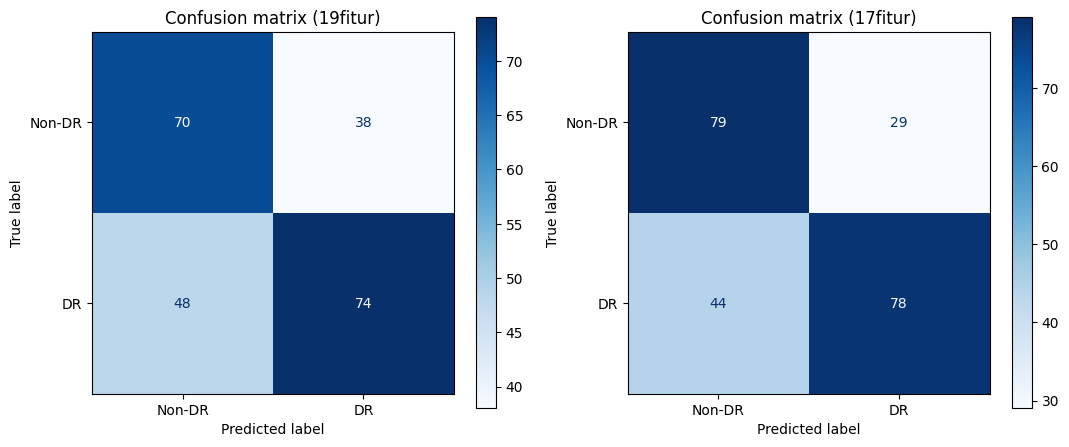

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (n, m) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, data[n][2], data[n][3],
        display_labels=["Non-DR", "DR"], cmap="Blues", ax=ax)
    ax.set_title(f"Confusion matrix ({n})")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## 10. Simpan dan unduh semua output

In [10]:
hasil.round(4).to_csv("hasil_dt.csv")
for n in data:
    imp_tables[n].round(6).to_csv(f"importance_{n}.csv")
    joblib.dump(tuned_models[n], f"dt_{n}.joblib")
    pd.Series(grids[n].best_params_).to_csv(f"best_params_{n}.csv")

out = ["hasil_dt.csv", "tuning_pruning_curve.png", "feature_importance.png", "confusion_matrix.png"] + \
      [f"{p}_{n}.{e}" for n in data for p, e in
       [("importance","csv"), ("dt","joblib"), ("best_params","csv"), ("tree","png")]]
with zipfile.ZipFile("output_decision_tree.zip", "w") as z:
    for f in out: z.write(f)
files.download("output_decision_tree.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>